# Week 9: Artificial Neural Networks(, Deep Learning)

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Scikit-learn implementations (LoR)

In this notebook we're going to focus on using an artificial neural network (ANN) implementation: the one provided by the [Scikit-learn](https://scikit-learn.org/stable/) package.

As well as learning how to use it, we'll revisit some different methods for evaluating and interpreting the models it produces.

In the extension exercises, there's a chance to try building deeper network architectures by making use of a graphics processing unit (GPU) to perform all the matrix multiplications involved as quickly as possible. To do this, we'll meet the two biggest deep learning frameworks: TensorFlow and Pytorch.

## Basic supervised learning recipe

The code below shows our basic supervised learning recipe again. This time we're using it to train and evaluate on the biopsies.csv data, and we're using [Scikit-learn](https://scikit-learn.org/stable/)'s artificial neural network implementation.

*   How accurate is the model? ** 95.6 %**

**Tip**: artificial neural networks are sensitive to predictive feature value ranges, and so we're using z-score standardisation via the `StandardScaler` class.

In [1]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create an Artificial Neural Network classifier model object (using hyperparameters to set the number of hidden layers,
# a logistic activation function, and ask to use stochastic gradient descent to search for the best parameters)
model = MLPClassifier(hidden_layer_sizes=(), solver='sgd', verbose=True, random_state=99)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

Iteration 1, loss = 0.99979793
Iteration 2, loss = 0.98426271
Iteration 3, loss = 0.96027786
Iteration 4, loss = 0.93127020
Iteration 5, loss = 0.89923726
Iteration 6, loss = 0.86300027
Iteration 7, loss = 0.82659594
Iteration 8, loss = 0.78962712
Iteration 9, loss = 0.75465175
Iteration 10, loss = 0.71968462
Iteration 11, loss = 0.68709826
Iteration 12, loss = 0.65623567
Iteration 13, loss = 0.62780449
Iteration 14, loss = 0.60079965
Iteration 15, loss = 0.57603610
Iteration 16, loss = 0.55372107
Iteration 17, loss = 0.53287320
Iteration 18, loss = 0.51365999
Iteration 19, loss = 0.49653126
Iteration 20, loss = 0.48040767
Iteration 21, loss = 0.46578085
Iteration 22, loss = 0.45252641
Iteration 23, loss = 0.44015795
Iteration 24, loss = 0.42903435
Iteration 25, loss = 0.41853410
Iteration 26, loss = 0.40889722
Iteration 27, loss = 0.39983497
Iteration 28, loss = 0.39159421
Iteration 29, loss = 0.38379198
Iteration 30, loss = 0.37656532
Iteration 31, loss = 0.37003361
Iteration 32, los

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


## Check the docs

The `MPLClassifier` class is just another standard Scikit-learn model implementation with all the usual methods and attributes we're used to (e.g., `fit()`, `predict()`, `predict_proba()`, `.classes_`, etc.).

Have a quick scan over the documentation: [`MLPClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

Hopefully you notice that a lot of the arguments are familiar gradient descent settings from your previous work (e.g., `solver`, `batch_size`, `learning_rate_init`, `max_iter`, `tol`, `n_iter_no_change`).

In the code above, we set the following constructor arguments to recreate the simplest possible ANN structure. This is a single artificial neuron, taking our predictive features as inputs and producing a single output via a logistic function, and is equivalent to training a logistic regressor (LoR):

*    `hidden_layer_sizes=()` - we don't want any hidden layers between the inputs and the output neuron (we are specifying an empty Python tuple, which you can think of, very roughly, as a non-editable version of a Python list);
*    `solver='sgd'` - we ask to use stochastic gradient descent again to speed up the recovery of model parameters (sampling mini-batches from our training data for estimating the local gradient);
*    `verbose=True` - we want to see some debug showing how the gradient descent process is progressing;
*    `random_state=99` - because we're doing random sampling we set the `random_state` for repeatable results.

**Tip**: the name `MLPClassifier` comes from the name 'multi-layer perceptron', another name for an artificial neural network.

**Tip**: the output neuron will use a logistic function by default (for positive class probabilities in the range 0-1)

## 1D model parameter visualisation

So our first network contains a single unit/neuron, and we can think of individual neurons as logistic regressors. We already understand logistic regressors really well: as linear regressors with their output going through a logistic function (see also our previous notebook).

The following model attributes - which hold the individual coefficients and offsets for the underlying linear relationships - should hopefully look familiar from our previous work with `LogisticRegression`/`SDGClassifier`:

*    `coefs_`
*    `intercepts_`

But notice that this time the attribute names are pluralised. They are Python lists, holding Numpy arrays that store the details of linear relationships for (potentially) _multiple_ nodes in each layer. In the language of neural networks, we'd call the values inside the matrices "weights" (though we can still interpret them as coefficients in a linear relationship). The matrices have the shape:

*   `(no. neurons in previous layer, no. neurons in next layer)`

In the code above we used the simplest possible network structure, where the input nodes (containing our predictive feature values) all connect to a single unit/neuron, so there is just a single weight matrix, holding the values we multiply our inputs by (before adding them together and feeding the result into the logistic function). Let's check this:

In [2]:
print(len(model.coefs_)) # list holds results for: just a single output neuron layer only

# size rule is: (no. neurons in previous layer, no. neurons in next layer)

print(model.coefs_[0].shape) # 30 weights/coefficients, one per predictive feature in the input layer, connecting to the single output neuron in the next layer

1
(30, 1)


Now let's visualise these weights/coefficients, in the same way we did in our previous notebook. Once again, we look at the top 10 strongest only:

**Tip**: you might spot we don't recover exactly the same values. Both classes are using gradient descent to converge on the same globally optimal solution, but they do it in different ways and stop at different points in the descent. We could play around with hyperparameters to recover results that are closer.

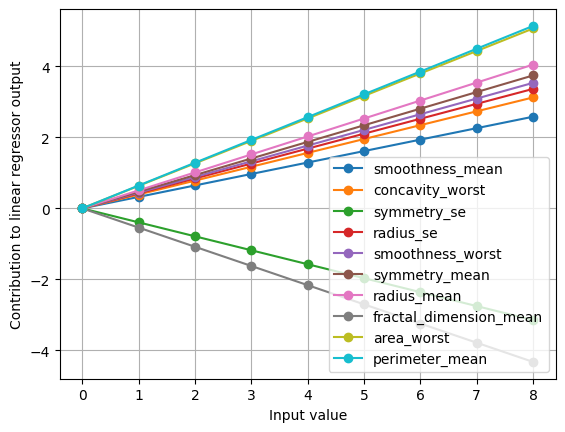

And the final constant offset is: -0.465


In [3]:
import matplotlib.pyplot as plt

# Grab a record of the predictive features
predictive_features = observations.drop(columns=target_feature).columns.to_numpy()

# get all the model parameters

# for an MLPClassifier with hidden_layer_sizes=(), coefs_[0] has shape:
# (n_features, n_outputs), or for us with the biopsies.csv data: (30, 1)
coef_ = model.coefs_[0][:, 0]
intercept_ = model.intercepts_[0][0]

# keep only the top 10 strongest
idx = np.argsort(np.abs(coef_))[-10:]
coef_ = coef_[idx]
predictive_features = predictive_features[idx]

# Show the strongest learned coefficients (model parameters) graphically
plt.figure()
for index, c in enumerate(coef_):
  plt.plot(range(0,9), range(0,9)*c, marker='o', linestyle='-', label=predictive_features[index])
plt.xlabel('Input value')
plt.ylabel('Contribution to linear regressor output')
plt.grid(True)
plt.legend()
plt.show()

# And the constant offset
print(f"And the final constant offset is: {intercept_:.3f}")

# Multiclass problems

For multiclass classification problems, Scikit-learn's `MLPClassifier` class applies a 'softmax' function at the output layer and optimises a cross-entropy cost function. There's no need for training multiple 'one-versus-all' models (e.g., as with the `SGDClassifier` or `SVC` classes in the previous notebook) and, in practice, artificial neural network classification with multiclass problems like the iris.csv data "just works".

# The moons.csv data

Let's switch to the moons.csv data (which has only two predictive features) and do some visualisation. We'll start to use some more interesting network structures and look at the final generalisations they produce.

## LoR behaviour

Let's start off with the simplest possible network again, and check that the result is as we expect.

*   **Before running the code - what do you expect the decision boundary to look like?** ** I expect it to be a relativly straight line seperating the two classes**

**Tip**: remember this architecture is equivalent to training an LoR.

Iteration 1, loss = 0.73214488
Iteration 2, loss = 0.73188019
Iteration 3, loss = 0.73150291
Iteration 4, loss = 0.73102457
Iteration 5, loss = 0.73045557
Iteration 6, loss = 0.72980533
Iteration 7, loss = 0.72908236
Iteration 8, loss = 0.72829434
Iteration 9, loss = 0.72744821
Iteration 10, loss = 0.72655021
Iteration 11, loss = 0.72560599
Iteration 12, loss = 0.72462065
Iteration 13, loss = 0.72359877
Iteration 14, loss = 0.72254449
Iteration 15, loss = 0.72146153
Iteration 16, loss = 0.72035326
Iteration 17, loss = 0.71922270
Iteration 18, loss = 0.71807258
Iteration 19, loss = 0.71690534
Iteration 20, loss = 0.71572320
Iteration 21, loss = 0.71452814
Iteration 22, loss = 0.71332195
Iteration 23, loss = 0.71210625
Iteration 24, loss = 0.71088248
Iteration 25, loss = 0.70965193
Iteration 26, loss = 0.70841580
Iteration 27, loss = 0.70717512
Iteration 28, loss = 0.70593084
Iteration 29, loss = 0.70468382
Iteration 30, loss = 0.70343483
Iteration 31, loss = 0.70218453
Iteration 32, los

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


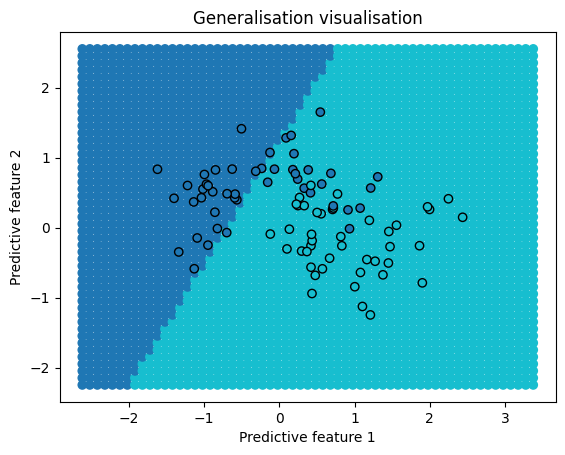

In [4]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Loading all the observations
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv')

# Set the name of the target feature
target_feature = 'Label'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create an Artificial Neural Network classifier model object (using hyperparameters to set the number of hidden layers,
# a logistic activation function, and ask to use stochastic gradient descent to search for the best model parameters)
model = MLPClassifier(hidden_layer_sizes=(), solver='sgd', verbose=True, random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# visualisation

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, grid_labels_int = np.unique(grid_predictions, return_inverse=True)
unique_labels, train_labels_int = np.unique(train_labels, return_inverse=True)
# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_labels_int, cmap='tab10')
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

Note the warning that the gradient descent hasn't finished: "*ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.*"

This is common to see, and isn't necessarily a problem. It essentially says: "the cost was still decreasing in pretty good amounts with each gradient descent step - are you sure you want to stop at 200 epochs?". I.e., we might not have reached the bottom of the cost surface valley we were descending.

In this case we might like to get a bit lower in the cost surface - looking at the generalisation, it's okay, but probably not as good as the standard logistic regressor result we saw last time.

Try adjusting the learning rate (which is 0.001 by default) to something a bit bigger using the following argument in your call to the constructor:
*    `learning_rate_init=0.01`

This allows for larger jumps (and more progress) during the 200 epochs. This is not without risks, and doesn't stop us getting a warning, but it allows us to improve performance on the testing data and gives the basic idea: model hyperparameters related specifically to the SGD process are important for recovering good model parameters.

What was the final cost score with the updated learning rate? **0.30836770**

## More complex network architectures

In the code listing below we experiment with adding a hidden layer containing 4 neurons.

We let the `MLPClassifier` use its default constructor arguments. It will use "relus" (rectified linear units) for the activation functions in the hidden layer, an alternative to sigmoids that make the local gradient calculations more stable. It will also use "Adam", a more powerful alternative to SGD which is capable of making more efficient jumps through the parameter space.

The only other change we make is to increase the number of epochs - we're happy to wait a bit longer for a good result:

Iteration 1, loss = 0.71997638
Iteration 2, loss = 0.71853391
Iteration 3, loss = 0.71709411
Iteration 4, loss = 0.71565706
Iteration 5, loss = 0.71422280
Iteration 6, loss = 0.71279141
Iteration 7, loss = 0.71136496
Iteration 8, loss = 0.70995004
Iteration 9, loss = 0.70853843
Iteration 10, loss = 0.70713009
Iteration 11, loss = 0.70572500
Iteration 12, loss = 0.70432315
Iteration 13, loss = 0.70292454
Iteration 14, loss = 0.70154522
Iteration 15, loss = 0.70017206
Iteration 16, loss = 0.69880292
Iteration 17, loss = 0.69743770
Iteration 18, loss = 0.69607628
Iteration 19, loss = 0.69471861
Iteration 20, loss = 0.69336461
Iteration 21, loss = 0.69201424
Iteration 22, loss = 0.69066810
Iteration 23, loss = 0.68932568
Iteration 24, loss = 0.68798744
Iteration 25, loss = 0.68665291
Iteration 26, loss = 0.68532195
Iteration 27, loss = 0.68399177
Iteration 28, loss = 0.68266373
Iteration 29, loss = 0.68134254
Iteration 30, loss = 0.68003131
Iteration 31, loss = 0.67872384
Iteration 32, los

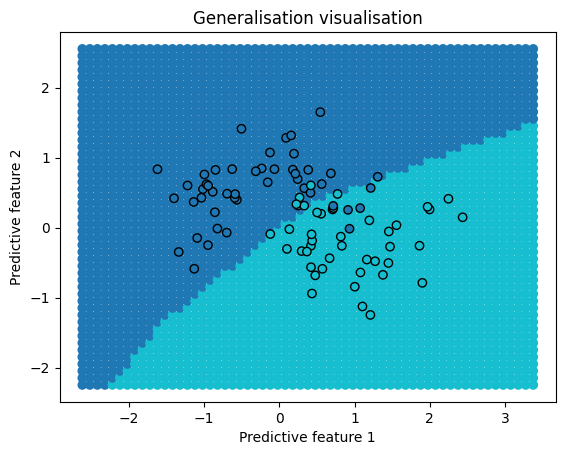

In [5]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Loading all the observations
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv')

# Set the name of the target feature
target_feature = 'Label'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create an Artificial Neural Network classifier model object (using hyperparameters to set the number of hidden layers)
model = MLPClassifier(hidden_layer_sizes=(4,), max_iter=2000, verbose=True, random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# visualisation

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation
plt.figure()

# Matplotlib wants integers for the colour codes in our scatter plot: convert our string-based labels over
unique_labels, grid_labels_int = np.unique(grid_predictions, return_inverse=True)
unique_labels, train_labels_int = np.unique(train_labels, return_inverse=True)
# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_labels_int, cmap='tab10')
# Plot the training data
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_labels_int, edgecolors='black', cmap='tab10')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

Let's just check the weights matrices are as we expect:

In [6]:
print(len(model.coefs_)) # list holds results for: a hidden layer with 4 neurons, then a single output neuron layer

# size rule is: (no. neurons in previous layer, no. neurons in next layer)

print(model.coefs_[0].shape) # 2 weights/coefficients, one per predictive feature in the input layer, connecting to each of the 4 hidden neurons in the next layer
print(model.coefs_[1].shape) # 4 weights/coefficients, one per hidden neuron in the last layer, connecting to the single output neuron in the next layer

2
(2, 4)
(4, 1)


## You try!

Copy/paste the last code listing into the code cell below, and try adjusting the `hidden_layer_sizes` argument of the model's constructor to find the final cost scores for the following architectures:

*    A single hidden layer with 4 neurons: final cost = ** 0.263 **
*    A single hidden layer with 40 neurons: final cost = ** 0.201 **
*    A single hidden layer with 200 neurons: final cost = ** 0.130 **
*    Three hidden layers, each with 200 neurons: final cost = ** 0.028 **

**Tip** defining a tuple with a single entry requires a trailing comma, e.g., `(5,)`.

**Tip** you might need to look at the [`MLPClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) documentation for exactly how to type the tuple for the final architecture.

In [10]:
# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Loading all the observations
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/moons.csv')

# Set the name of the target feature
target_feature = 'Label'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create an Artificial Neural Network classifier model object (using hyperparameters to set the number of hidden layers)
model = MLPClassifier(hidden_layer_sizes=(200,200,200), max_iter=2000, verbose=True, random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# visualisation

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.1
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

Iteration 1, loss = 0.70267277
Iteration 2, loss = 0.66531486
Iteration 3, loss = 0.63205971
Iteration 4, loss = 0.60115101
Iteration 5, loss = 0.57161302
Iteration 6, loss = 0.54266723
Iteration 7, loss = 0.51371637
Iteration 8, loss = 0.48476214
Iteration 9, loss = 0.45633553
Iteration 10, loss = 0.42888205
Iteration 11, loss = 0.40284286
Iteration 12, loss = 0.37864767
Iteration 13, loss = 0.35644920
Iteration 14, loss = 0.33651038
Iteration 15, loss = 0.31901365
Iteration 16, loss = 0.30391485
Iteration 17, loss = 0.29103688
Iteration 18, loss = 0.27993753
Iteration 19, loss = 0.27033536
Iteration 20, loss = 0.26184399
Iteration 21, loss = 0.25408257
Iteration 22, loss = 0.24693604
Iteration 23, loss = 0.24020186
Iteration 24, loss = 0.23376249
Iteration 25, loss = 0.22766014
Iteration 26, loss = 0.22204260
Iteration 27, loss = 0.21687661
Iteration 28, loss = 0.21218372
Iteration 29, loss = 0.20798729
Iteration 30, loss = 0.20432606
Iteration 31, loss = 0.20120193
Iteration 32, los

# Extension tasks (optional)

(Extension tasks are optional. They don't map to the assessment on this module and there is no harm in skipping them. However, for people who are interested in the subject/planning to do further study, the extension tasks can help you deepen your machine learning knowledge and meet the module learning objectives more fully.)

## ANNs for regression

Let's quickly meet the `MLPRegressor` class for regression problems. You can think of it as essentially the same as the `MLPClassifier` class, but producing networks with no logistic activation function in the final output layer node (so that the final output can be over any range of values, not just 0-1).

Check you can interpret the network structure from the constructor arguments and have a look at the resulting generalisation:

In [ ]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPRegressor
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/sepal_regression.csv')

# Set the name of the target feature
target_feature = 'petal_length'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing values ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_values = observations_test[target_feature].to_numpy()

# Split into training examples and training values ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_values = observations_train[target_feature].to_numpy()

# Create an Artificial Neural Network regressor model object (you should be able to interpret the hyperparameters)
model = MLPRegressor(hidden_layer_sizes=(200,200,200), max_iter=2000, random_state=99)

# Fit the model to our training data
model.fit(train_examples, train_values)

# Use the model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the mean squared error (MSE) between the model's predictions and the testing values
mse = ((predictions - test_values) ** 2).mean()
# Display the MSE as a single quantitative measure of overall performance
print("Mean square error (MSE):", mse)
# Let's also see the square root of the MSE, which is easier for us to interpret
print("Root MSE: ", np.sqrt(mse))

# visualisation

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.05
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation
plt.figure()

# What are the biggest/smallest outputs we're dealing with - to help us get colour scaling correct
vmin = min(grid_predictions.min(), train_values.min())
vmax = max(grid_predictions.max(), train_values.max())

# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_predictions, edgecolors='none', cmap='viridis', vmin=vmin, vmax=vmax)
# Plot the training data for context
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_values, edgecolors='black', cmap='viridis', vmin=vmin, vmax=vmax)

# Add a colorbar to help us interpret the colours
plt.colorbar(label='Petal length')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

# now as a (rotatable) 3D Surface Plot with Plotly

# plot the model generalisation (3D) and the training data
fig = go.Figure(data=[
    go.Surface(x=grid_x, y=grid_y, z=grid_predictions.reshape(grid_x.shape), colorscale="Viridis", cmin=vmin, cmax=vmax),
    go.Scatter3d(
        x=train_examples[:, 0],
        y=train_examples[:, 1],
        z=train_values,
        mode="markers",
        marker=dict(
            size=5,
            color=train_values,
            colorscale="Viridis",
            cmin=vmin,
            cmax=vmax,
            showscale=True,
            line=dict(
                color="black",
                width=1
            )
        )
    )
])

# add some axis labels
fig.update_layout(
    title="Generalisation visualisation",
    scene=dict(
        xaxis_title='Predictive feature 1',
        yaxis_title='Predictive feature 2',
        zaxis_title='Petal length',
        aspectmode='cube'
    )
)

fig.show()

## Classifying images

Let's try using an ANN on a more interesting classification problem: classifying images of real-world objects.

The CIFAR-10 dataset contains colour images from 10 different classes:

*    airplane
*    automobile
*    bird
*    cat
*    deer
*    dog
*    frog
*    horse
*    ship
*    truck

Have a quick look at the details here: [CIFAR-10](https://paperswithcode.com/dataset/cifar-10).

Let's try and classify between the different types of image. We'll try Scikit-learn's ANN implementation again, and we'll also introduce a couple of deep learning frameworks to see if we can speed up the training process by using a GPU.

## Loading an image dataset

There are various Python packages that will let you load up image datasets directly into memory (from an online repository) without having to deal with the individual image files.

For example, the code snippet below uses the HuggingFace `datasets` package to load up the CIFAR-10 data as a series of training/testing examples (each one containing all the pixel values in an image) and training/testing labels (based on the name of the object shown in the image).

The code takes a while to execute the first time you run it (while the data is downloaded from the online repository), but the data is then cached on the local system (our Colab virtual machine) and is faster to access on every subsequent run.

*    Try running the code (downloading the data from an online repository) - how long does it take to finish? **Type your answer here**
*    Try running the code again (loading the data up from a local cached version) - how long does it take to finish? **Type your answer here**

**Tip**: don't worry about any warnings you see - they're just a reminder that we can get faster repository access if we authenticate. We don't need this; we're just playing around.


In [ ]:
import numpy as np
from datasets import load_dataset
from sklearn.preprocessing import StandardScaler
import time

# start timing
start_time = time.time()

# load dataset (with the train/test split already made)
ds = load_dataset("uoft-cs/cifar10")

image_col = "img"

# convert to NumPy arrays
train_examples = np.stack([np.array(img) for img in ds["train"][image_col]])
# grab the associated labels
train_labels = np.array(ds["train"]["label"])

# convert to NumPy arrays
test_examples = np.stack([np.array(img) for img in ds["test"][image_col]])
# grab the associated labels
test_labels = np.array(ds["test"]["label"])

# flatten images, so we have one observation per row, as we're used to
train_examples = train_examples.reshape(train_examples.shape[0], -1)
test_examples = test_examples.reshape(test_examples.shape[0], -1)

# stop timing
end_time = time.time()

# calculate the elapsed time for data loading
load_time = end_time - start_time
print("Data loading took", load_time, "seconds")

# standardise our predictive features, ready for training ANNs
scaler = StandardScaler()
train_examples = scaler.fit_transform(train_examples)
test_examples = scaler.transform(test_examples)

## Scikit-learn ANN (CPU)

As a baseline, let's optimise a 3-layer network using Scikit-learn. We'll run the training for just 10 epochs (with a mini-batch size of 128) just to get an idea of how long training takes. Scikit-learn is well optimised for CPU training and the time taken is about as good as we could hope for:

*    How long did the model training phase take? **Type your answer here**

In [ ]:
# relying on the data loading we did above...

import numpy as np
from sklearn.neural_network import MLPClassifier
import time

# start timing
train_start_time = time.time()

# create an ANN model object
model = MLPClassifier(hidden_layer_sizes=(100,100,100), max_iter=10, batch_size=128, verbose=True, random_state=99)

# call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# stop timing
train_end_time = time.time()

# calculate the elapsed time for training
train_time = train_end_time - train_start_time
print("Training took", train_time, "seconds")

# start timing for prediction
predict_start_time = time.time()

# use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# stop timing for prediction
predict_end_time = time.time()

# calculate the elapsed time for prediction
predict_time = predict_end_time - predict_start_time
print("Prediction took", predict_time, "seconds")

# Find the total number of model predictions that matched with the corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

## TensorFlow ANN (GPU)

Now let's try using a deep learning framework - Google's TensorFlow - to make the same model, but see if we can improve the training time by using a GPU to help speed up all the matrix multiplications involved.

**To give this code cell access to a GPU you will need to click the down arrow up in the top right-hand corner, and select "Change runtime type" and select an option with a GPU (or TPU if none is available).**

Now you can run the code cell below:

*    How long did the model training phase take? **Type your answer here**

In [ ]:
# relying on the data loading we did above...

# Importing the packages we use
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

# Check if GPU is available
gpus = tf.config.list_physical_devices('GPU')
# Show some debug
if not gpus:
  print("No GPU available, using CPU only")

# Re-seed for reproducible results
tf.random.set_seed(99)
# Build a feed-forward network
model = tf.keras.Sequential()
# Input layer sizing based on the number of pixels in our images
model.add(tf.keras.layers.InputLayer(shape=(3072,)))
# Then, keeping things relatively simple/shallow initially, 3 hidden layers with 100 nodes and relu activations
model.add(tf.keras.layers.Dense(100, activation="relu"))
model.add(tf.keras.layers.Dense(100, activation="relu"))
model.add(tf.keras.layers.Dense(100, activation="relu"))
# And an output layer using a "softmax" function to ensure we get class probabilities that sum to 1
model.add(tf.keras.layers.Dense(10, activation="softmax"))

# Compile the model, asking to use cross-entropy as our cost function, and Adam for gradient descent
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# Start timing
train_start_time = time.time()

# Call the model's fitting algorithm, passing in our training examples and training labels, and retaining information about the descent
history = model.fit(train_examples, train_labels, epochs=10, batch_size=128)

# Stop timing
train_end_time = time.time()

# Calculate the elapsed time for training
train_time = train_end_time - train_start_time
print("Training took", train_time, "seconds")

# Visualise the gradient descent process
plt.figure()
plt.plot(history.history['loss'], label='Training Cost')
plt.title('Cost')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.legend()
plt.show()

# Start timing for prediction
predict_start_time = time.time()

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Stop timing for prediction
predict_end_time = time.time()

# Calculate the elapsed time for prediction
predict_time = predict_end_time - predict_start_time
print("Prediction took", predict_time, "seconds")

# Convert probabilities to predicted class labels (they are arrays of class probability scores by default)
predictions = np.argmax(predictions, axis=1)

# Find the total number of model predictions that matched with the corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

## Pytorch ANN (GPU)

Now let's try another deep learning framework - Facebook's Pytorch - to make the same model again, and see how the training time compares.

**Make sure you're already connected to a runtime with a GPU. If you're not sure, then click the down arrow in the top right-hand corner and select "View resources", and, if necessary, "Change runtime type".**

Now you can run the code cell below:

*    How long did the model training phase take? **Type your answer here**

In [ ]:
# relying on the data loading we did above...

# Importing the packages we use
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import time

# Check if GPU is available and set the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Show some debug
if device.type != 'cuda':
  print("No GPU available, using CPU only")

# Re-seed for reproducible results
torch.manual_seed(99)

# Convert to PyTorch tensors and move them to the device
train_examples = torch.tensor(train_examples, dtype=torch.float32).to(device)
test_examples = torch.tensor(test_examples, dtype=torch.float32).to(device)
train_labels = torch.tensor(train_labels, dtype=torch.long).to(device)
test_labels = torch.tensor(test_labels, dtype=torch.long).to(device)

# Create DataLoader for batch processing (and set the batch size)
train_dataset = TensorDataset(train_examples, train_labels)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

# Build a feed-forward network
model = nn.Sequential(
    # Input layer sizing based on the number of pixels in our images
    nn.Linear(3072, 100),
    nn.ReLU(),
    # Then, keeping things relatively simple/shallow initially, 3 hidden layers with 100 nodes and relu activations
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    # And an output layer producing raw class scores (no activation function) for 10 classes (softmax is applied internally by CrossEntropyLoss)
    nn.Linear(100, 10)
).to(device)

# Asking to use cross-entropy as our cost function, and Adam for gradient descent
cost = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

# Call the model's fitting algorithm manually, one bactch at a time, and retaining information about the descent
num_epochs = 10
model.train()

# Initialize a list to store the average loss per epoch
epoch_losses = []

# Start timing
train_start_time = time.time()

for epoch in range(num_epochs):
    running_loss = 0.0
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = cost(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    avg_loss = running_loss / len(train_loader)
    epoch_losses.append(avg_loss)  # Store the average loss for this epoch
    print("Epoch", epoch+1, "/", num_epochs, "Loss:", avg_loss)

# Stop timing
train_end_time = time.time()

# Calculate the elapsed time for training
train_time = train_end_time - train_start_time
print("Training took", train_time, "seconds")

# Visualize training loss
plt.figure()
plt.plot(range(num_epochs), epoch_losses, label='Cost')  # Plot the stored losses
plt.title('Training Cost')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.legend()
plt.show()

# Start timing for prediction
predict_start_time = time.time()

# Evaluating the model
model.eval()
with torch.no_grad():
    # Ensure test_examples are on the same device as the model
    test_examples = test_examples.to(device)
    outputs = model(test_examples)
    _, predicted = torch.max(outputs, 1)

    # Calculate correct predictions
    correct_predictions = torch.sum(predicted == test_labels).item()  # Convert to Python number with .item()

    # Calculate accuracy
    accuracy = correct_predictions / len(test_labels)

    # Print the accuracy
    print("Accuracy:", accuracy, "(or", round(accuracy * 100, 1), "%)")

# Stop timing for prediction
predict_end_time = time.time()

# Calculate the elapsed time for prediction
predict_time = predict_end_time - predict_start_time
print("Prediction took", predict_time, "seconds")

## Local GPU use

If you have a GPU on your local machine (e.g., you're using an MMU lab machine) then you can potentially get even better performance (and avoid time-limited Colab sessions) by running your code locally.

The big downside to running code locally is that you have to install and manage all of your own Python packages (often harder than it sounds). At MMU, the technicians have kindly set up a Python virtual environment ("venv") for us to run both TensorFlow and Pytorch code locally, under Linux.

There is an extra page on Moodle taking you through the steps needed to run the last two code cells (TensorFlow and Pytorch versions of the model) locally. Have a look and see what performance you get on a lab machine.

*    How long did the Pytorch model training phase take? **Type your answer here**
*    How long did the TensorFlow model training phase take? **Type your answer here**

## Next steps

We've focused on training times, but how was classification performance? Much better than random chance (10% with 10 image categories) but still not great at a little over 50%.

There are ANN architectures designed specifically for images which can improve performance by a _lot_. For example, convolutional neural networks, or CNNs. You can find out more about them in either the Geron book (TensorFlow-focused) or the Raschka et al. book (Pytorch-focused) on the module reading list. And much more still in your Deep Learning module next year :)